# Seasonal and weather effects on bike-sharing demand
### A two-way ANOVA project

Tools: Python, Pandas, Matplotlib, Seaborn, SciPy, Statsmodels
Statistical method: two-way factorial ANOVA
Dataset: UCI Bike sharing dataset (2011-2012)

Business objective: investigate whether average daily bike_sharing demand differs significantly across seasons and weather conditions.

## Reasearch questions and hypotheses
### Research questions
1. Does average daily rental demand differ significantly across seasons?
2. Does average daily rental demand differ between clear anf misty/cloudy weather conditions?
3. Does the relationship between weather conditions and rental demand very across seasons?

### Statistical hypotheses
H1: main effect of season
- H0: the adjusted mean rental demand is equal across seasons
- H1: at least one seasonal adjusted mean differs

H2: main effect of weather
- H0: the adjusted mean demand is equal between wether groups
- H1: the adjusted mean demand differs between weather groups

H3: season x weather interaction
- H0: the difference between weather groups is the same across all seasons
- H1: the difference between weather groups varies by season

Significance level (alpha) = 0.50

## Dataset description

### Data source
Dataset: Bike sharing dataset

Source: UCI Machine learning repository

Period : January 2011 - December 2012

URL: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset

The dataset contain historical bike rental counts together with weather and calendar information.

### Variables of interest
| Variable | Description | Analytical Role |
|---|---|---|
| `cnt` | Total daily bike rentals | Dependent variable |
| `season` | Season category | Independent variable |
| `weathersit` | Weather category | Independent variable |
| `dteday` | Observation date | Time identifier |
| `yr` | Year of observation | Potential control |
| `workingday` | Workday indicator | Potential control |

### Analytical scope
The primary analysis will compare four seasons and two weather categories: clear and misty/cloudy conditions (to avoid relying on very sparcely populated groups)

### 1. Data loading and initial inspection

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

sns.set_theme(style="whitegrid")

cwd = Path.cwd()

if (cwd / "01_data" / "01_raw" / "day.csv").exists():
    project_root = cwd
elif (cwd.parent / "01_data" / "01_raw" / "day.csv").exists():
        project_root = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find. "
        "Check your folder structure. "
    )
data_path = project_root / "01_data" / "01_raw" /"day.csv"

df = pd.read_csv(data_path, parse_dates=["dteday"])

print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), float64(4), int

### 2. Data quality assessment

In [3]:
#checking the data
print("Rows and columns:", df.shape)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate dates:", df["dteday"].duplicated().sum())

print("\nNegative rental counts:", (df["cnt"] < 0).sum())

print(
    "\nInconsistent totals:",
    (df["cnt"] != df["casual"] + df["registered"]).sum()
)

print("\nSeasons:")
print(df["season"].value_counts().sort_index())

Rows and columns: (731, 16)

Missing values:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Duplicate dates: 0

Negative rental counts: 0

Inconsistent totals: 0

Seasons:
season
1    181
2    184
3    188
4    178
Name: count, dtype: int64


### 3. Data preparation


**Factor A: Season**
- Winter
- Spring
- Summer
- Fall

**Factor B: Weather**
- Clear
- Misty / Cloudy

**Dependent Variable:**
- Total daily rental count (`cnt`)

In [4]:
#creating readable categories
season_map = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
weather_map = {1: "Clear", 2: "Misty / Cloudy", 3: "Light precipitation", 4:"Severe weather"}

df["season_label"] = df["season"].map(season_map)
df["weather_label"] = df["weathersit"].map(weather_map)

season_order = ["Winter", "Spring", "Summer", "Fall"]
weather_order = ["Clear", "Misty / Cloudy"]

assert df["season_label"]. notna().all()
assert df["weather_label"].notna().all()

display(
    df[["dteday", "season_label", "weather_label", "cnt"]].head()
)

,dteday,season_label,weather_label,cnt
0,2011-01-01,Winter,Misty / Cloudy,985
1,2011-01-02,Winter,Misty / Cloudy,801
2,2011-01-03,Winter,Clear,1349
3,2011-01-04,Winter,Clear,1562
4,2011-01-05,Winter,Clear,1600


In [5]:
#checking how many observations are for each combination of factors
cell_counts = pd.crosstab(
    df["season_label"],
    df["weather_label"]
)

display(cell_counts)

weather_label,Clear,Light precipitation,Misty / Cloudy
season_label,,,
Fall,103,10,65
Spring,113,3,68
Summer,136,4,48
Winter,111,4,66


In [6]:
# primary anova
anova_df = df[df["weathersit"].isin([1,2])].copy()

design_counts = pd.crosstab(
    anova_df["season_label"],
    anova_df["weather_label"]
).reindex(
    index=season_order,
    columns=weather_order,
    fill_value=0
)

display(design_counts)

assert (design_counts >= 10).all().all(), (
    "Some groups contain fewer than 10 days. "
    "Review the factorial design."
)

print("Observations used: ", len(anova_df))
print("Observations excluded: ", len(df) - len(anova_df))

weather_label,Clear,Misty / Cloudy
season_label,,
Winter,111,66
Spring,113,68
Summer,136,48
Fall,103,65


Observations used:  710
Observations excluded:  21


### 4.EDA

Objective: Understand the distribution and variability of daily bike rental demand.

In [7]:
summary = (
    anova_df
    .groupby(
        ["season_label", "weather_label"], observed=True
    )["cnt"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(summary)

count     mean  median      std
season_label weather_label                                  
Fall         Clear             103  5043.56  5041.0  1595.69
             Misty / Cloudy     65  4654.00  4563.0  1523.45
Spring       Clear             113  5548.55  5585.0  1467.66
             Misty / Cloudy     68  4236.71  4205.5  1579.04
Summer       Clear             136  5878.26  5534.5  1356.65
             Misty / Cloudy     48  5222.48  4792.5  1431.16
Winter       Clear             111  2811.14  2417.0  1409.96
             Misty / Cloudy     66  2357.17  2020.5  1313.33

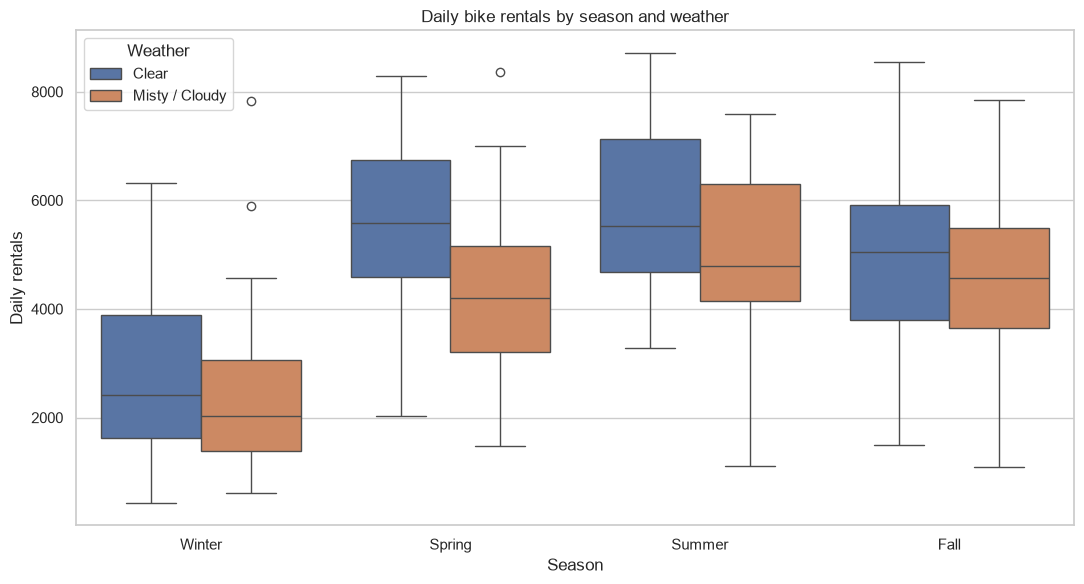

In [8]:
#visualizing the distribution of rentals
plt.figure(figsize=(11,6))

sns.boxplot(
    data=anova_df,
    x="season_label",
    y ="cnt",
    hue="weather_label",
    order=season_order,
    hue_order=weather_order
)

plt.title("Daily bike rentals by season and weather")
plt.xlabel("Season")
plt.ylabel("Daily rentals")
plt.legend(title="Weather")
plt.tight_layout()
plt.show()

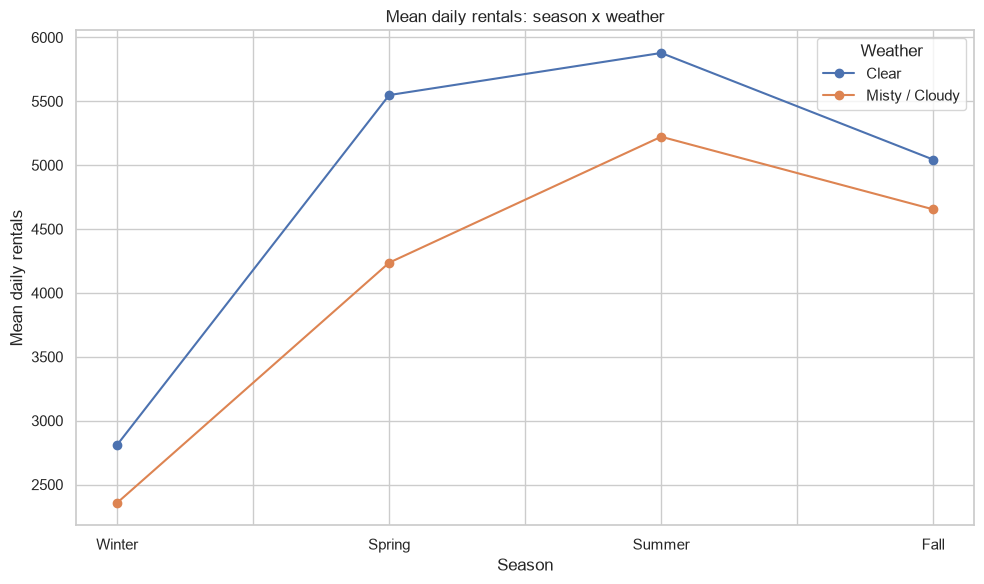

In [9]:
#visualizing the mean demand and potential interaction
means = (
    anova_df
    .groupby(["season_label", "weather_label"])["cnt"]
    .mean()
    .unstack()
    .reindex(season_order)
)

ax = means[weather_order].plot(
    kind="line",
    marker="o",
    figsize=(10,6)
)

plt.title("Mean daily rentals: season x weather")
plt.xlabel("Season")
plt.ylabel("Mean daily rentals")
plt.legend(title="Weather")
plt.tight_layout()
plt.show()

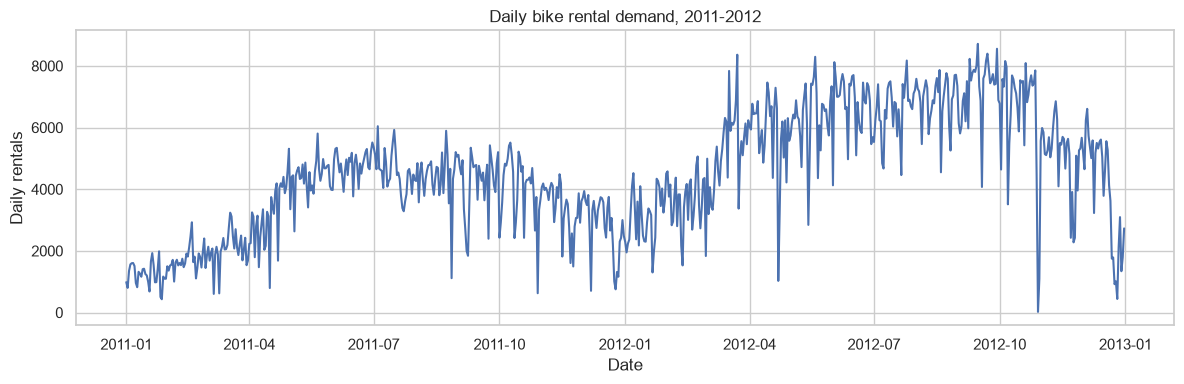

In [10]:
#visualizing the chronological patterns
plt.figure(figsize=(12,4))

sns.lineplot(
    data=df.sort_values("dteday"),
    x="dteday",
    y="cnt"
)

plt.title("Daily bike rental demand, 2011-2012")
plt.xlabel("Date")
plt.ylabel("Daily rentals")
plt.tight_layout()
plt.show()

Which season has the highest mean daily demand? Summer
Is the difference between clear and cloudy weather similar in every season? Yes
Which season–weather combination exhibits the greatest variation? Spring
Are some combinations represented by substantially fewer days? Fall
Does demand appear to change over time, independently of seasonality? Independently, more demand in 2012 overall

### 5. ANOVA analysis

#### Statistical model
$$
Y_{ijk} = \mu + \alpha_i + \beta_j +
(\alpha\beta)_{ij} + \varepsilon_{ijk}
$$

Where:

- $Y_{ijk}$: Daily rental count.
- $\mu$: Overall mean.
- $\alpha_i$: Season effect.
- $\beta_j$: Weather effect.
- $(\alpha\beta)_{ij}$: Interaction effect.
- $\varepsilon_{ijk}$: Random error.

#### Model specification
The analysis will use ordinary least squares with categorical factors and an interaction term. Type III sums of squares and sum-to-zero constrasts will be used to evaluate the model terms. Because the design may be unbalanced main-effect results will be interpreted as adjusted comparisons with special attention to any significant interaction.

In [11]:
formula = (
    "cnt ~  C(season_label, Sum) * " \
    "C(weather_label, Sum)"
)

model = ols(formula,
        data=anova_df
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.415
Model:                            OLS   Adj. R-squared:                  0.409
Method:                 Least Squares   F-statistic:                     71.17
Date:                Sun, 25 Oct 2026   Prob (F-statistic):           1.38e-77
Time:                        17:36:32   Log-Likelihood:                -6175.6
No. Observations:                 710   AIC:                         1.237e+04
Df Residuals:                     702   BIC:                         1.240e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                                                    coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------

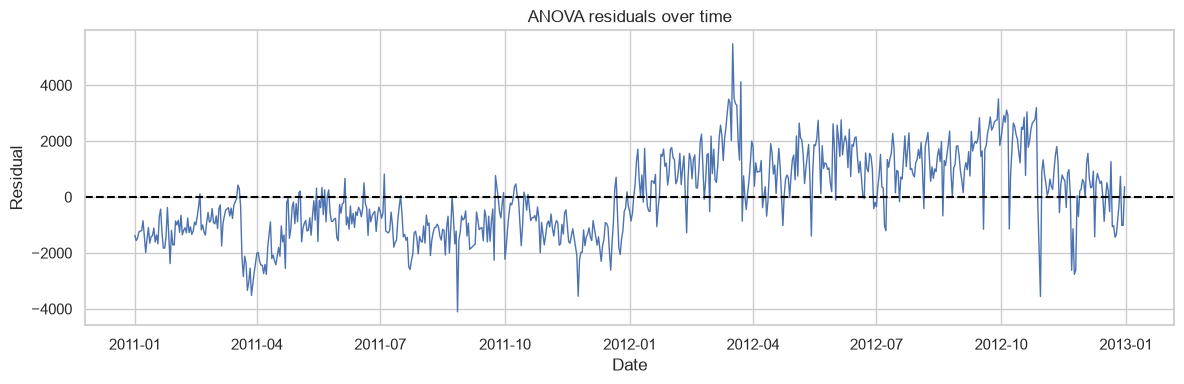

Durbin-Watson:  0.407


In [ ]:
#inspecting the independence of observations
from statsmodels.stats.stattools import durbin_watson

residual_df = anova_df[
    ["dteday"]
].copy()

residual_df["residual"] = model.resid

residual_df = residual_df.sort_values("dteday")

plt.figure(figsize=(12,4))

plt.plot(
    residual_df["dteday"],
    residual_df["residual"],
    linewidth=1
)

plt.axhline(0, color="black", linestyle="--")
plt.title("ANOVA residuals over time")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

print(
    "Durbin-Watson: ",
    round(durbin_watson(residual_df["residual"]), 3)
)

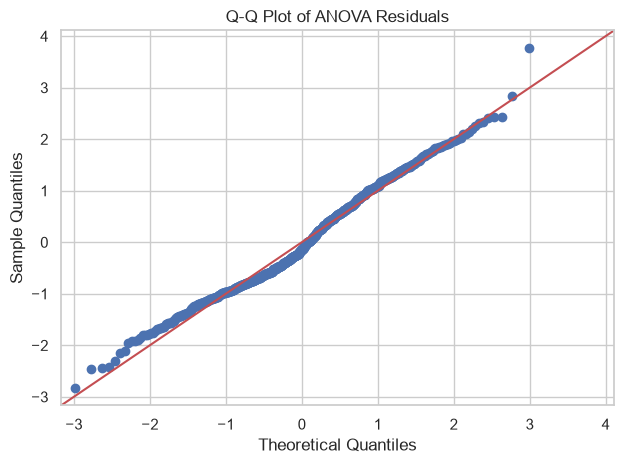

In [ ]:
#checking the normality assumption using q-q plot
sm.qqplot(
    model.resid,
    line="45",
    fit=True
)

plt.title("Q-Q Plot of ANOVA Residuals")
plt.tight_layout()
plt.show()

In [18]:
#checking homogeneity of variance using the Levene's test
groups = [
    group["cnt"].to_numpy()
    for _, group in anova_df.groupby(
        ["season_label", "weather_label"]
    )
]

levene_stat, levene_p = stats.levene(
    *groups,
     center="median"
)

print("Levene statistic: ", round(levene_stat, 3))
print("p-value: ", round(levene_p, 4))

Levene statistic:  0.972
p-value:  0.4507


In [19]:
anova_results = anova_lm(model, typ=3)
display(anova_results.round(4))

,sum_sq,df,F,PR(>F)
Intercept,1.265595e+10,1.0,5954.4093,0.0000
"C(season_label, Sum)",8.065171e+08,3.0,126.4842,0.0000
"C(weather_label, Sum)",7.824677e+07,1.0,36.8138,0.0000
"C(season_label, Sum):C(weather_label, Sum)",2.228610e+07,3.0,3.4951,0.0153
Residual,1.492084e+09,702.0,NaN,NaN


In [22]:
ss_error = anova_results.loc["Residual", "sum_sq"]

effects = anova_results.drop(
    index=["Intercept", "Residual"]
).copy()

effects["partial_eta_squared"] = (
    effects["sum_sq"] / 
    (effects["sum_sq"] + ss_error)
)

display(
    effects[
        ["F", "PR(>F)", "partial_eta_squared"]
    ].round(4)    
)

,F,PR(>F),partial_eta_squared
"C(season_label, Sum)",126.4842,0.0000,0.3509
"C(weather_label, Sum)",36.8138,0.0000,0.0498
"C(season_label, Sum):C(weather_label, Sum)",3.4951,0.0153,0.0147


In [23]:
anova_hc3 = anova_lm(
    model,
    typ=3,
    robust="hc3"
)

display(anova_hc3.round(4))

,sum_sq,df,F,PR(>F)
Intercept,1.237740e+10,1.0,5823.3552,0.000
"C(season_label, Sum)",8.872291e+08,3.0,139.1421,0.000
"C(weather_label, Sum)",7.652459e+07,1.0,36.0035,0.000
"C(season_label, Sum):C(weather_label, Sum)",2.039062e+07,3.0,3.1978,0.023
Residual,1.492084e+09,702.0,NaN,NaN
